In [1]:

# Install required libraries
!pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning algorithms
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.tree import DecisionTreeClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

# Model saving
import joblib

# Warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")



All libraries imported successfully!


In [2]:

import io

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()



NameError: name 'uploaded' is not defined

In [3]:


import pandas as pd

# Load the already uploaded dataset
df = pd.read_csv('/content/kidney_disease.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())



Dataset loaded successfully!
Dataset Shape: (400, 26)


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [4]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all'))


Dataset Shape: (400, 26)

Column Names:
['id', 'age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'classification']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc            

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
count,400.000000,391.000000,388.000000,353.000000,354.000000,351.000000,248,335,396,396,...,330,295,270,398,398,398,399,399,399,400
unique,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,2,...,44,92,49,2,5,3,2,2,2,3
top,NaN,NaN,NaN,NaN,NaN,NaN,normal,normal,notpresent,notpresent,...,41,9800,5.2,no,no,no,good,no,no,ckd
freq,NaN,NaN,NaN,NaN,NaN,NaN,201,259,354,374,...,21,11,18,251,258,362,317,323,339,248
mean,199.500000,51.483376,76.469072,1.017408,1.016949,0.450142,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,115.614301,17.169714,13.683637,0.005717,1.352679,1.099191,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,2.000000,50.000000,1.005000,0.000000,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,99.750000,42.000000,70.000000,1.010000,0.000000,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,199.500000,55.000000,80.000000,1.020000,0.000000,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,299.250000,64.500000,80.000000,1.020000,2.000000,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': (missing_values / len(df)) * 100
})

missing_report = missing_report[
    missing_report['Missing Values'] > 0
].sort_values(
    by='Missing Values',
    ascending=False
)

print("Missing Value Report:")
display(missing_report)


Missing Value Report:


,Missing Values,Percentage (%)
rbc,152,38.00
rc,130,32.50
wc,105,26.25
pot,88,22.00
sod,87,21.75
pcv,70,17.50
pc,65,16.25
hemo,52,13.00
su,49,12.25
sg,47,11.75


Target Column Distribution:
classification
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64


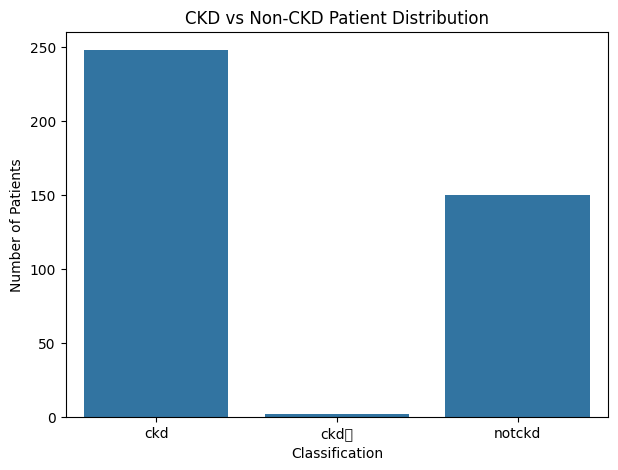

In [6]:

print("Target Column Distribution:")
print(df['classification'].value_counts(dropna=False))

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='classification')

plt.title('CKD vs Non-CKD Patient Distribution')
plt.xlabel('Classification')
plt.ylabel('Number of Patients')

plt.show()


In [7]:

# Create a copy of the original dataset
data = df.copy()

# Remove unnecessary ID column
data.drop(columns=['id'], inplace=True)

# Clean target variable
data['classification'] = (
    data['classification']
    .astype(str)
    .str.strip()
    .str.lower()
)

# Convert numerical columns stored as objects
numeric_columns = ['pcv', 'wc', 'rc']

for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Clean categorical columns
categorical_columns = data.select_dtypes(
    include=['object']
).columns.drop('classification')

for col in categorical_columns:
    data[col] = (
        data[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .replace('nan', np.nan)
    )

print("Data cleaning completed!")
print("New dataset shape:", data.shape)

print("\nTarget distribution:")
print(data['classification'].value_counts())


Data cleaning completed!
New dataset shape: (400, 25)

Target distribution:
classification
ckd       250
notckd    150
Name: count, dtype: int64


In [8]:

categorical_columns = data.select_dtypes(
    include=['object']
).columns.drop('classification')

for col in categorical_columns:
    print(f"\n{col}:")
    print(data[col].value_counts(dropna=False))



rbc:
rbc
normal      201
NaN         152
abnormal     47
Name: count, dtype: int64

pc:
pc
normal      259
abnormal     76
NaN          65
Name: count, dtype: int64

pcc:
pcc
notpresent    354
present        42
NaN             4
Name: count, dtype: int64

ba:
ba
notpresent    374
present        22
NaN             4
Name: count, dtype: int64

htn:
htn
no     251
yes    147
NaN      2
Name: count, dtype: int64

dm:
dm
no     261
yes    137
NaN      2
Name: count, dtype: int64

cad:
cad
no     364
yes     34
NaN      2
Name: count, dtype: int64

appet:
appet
good    317
poor     82
NaN       1
Name: count, dtype: int64

pe:
pe
no     323
yes     76
NaN      1
Name: count, dtype: int64

ane:
ane
no     339
yes     60
NaN      1
Name: count, dtype: int64


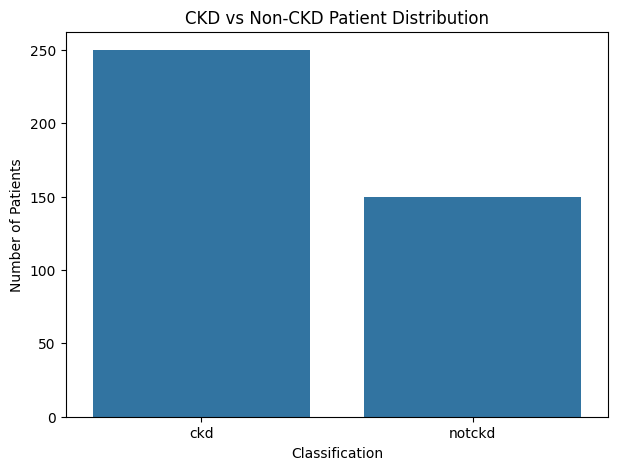

In [9]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x='classification',
    order=['ckd', 'notckd']
)

plt.title('CKD vs Non-CKD Patient Distribution')
plt.xlabel('Classification')
plt.ylabel('Number of Patients')

plt.savefig('target_distribution.png', dpi=300)
plt.show()


In [10]:

X = data.drop(columns=['classification'])

y = data['classification'].map({
    'ckd': 1,
    'notckd': 0
})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Mapping:")
print("CKD = 1")
print("Not CKD = 0")

print("\nTarget Distribution:")
print(y.value_counts())


Features Shape: (400, 24)
Target Shape: (400,)

Target Mapping:
CKD = 1
Not CKD = 0

Target Distribution:
classification
1    250
0    150
Name: count, dtype: int64


In [11]:

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nTotal Numerical Features:", len(numerical_features))

print("\nCategorical Features:", categorical_features)
print("\nTotal Categorical Features:", len(categorical_features))


Numerical Features: ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']

Total Numerical Features: 14

Categorical Features: ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']

Total Categorical Features: 10


In [12]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Features: (320, 24)
Testing Features: (80, 24)

Training Target Distribution:
classification
1    200
0    120
Name: count, dtype: int64

Testing Target Distribution:
classification
1    50
0    30
Name: count, dtype: int64


In [13]:

# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)


Preprocessing completed!
Training Data Shape: (320, 34)
Testing Data Shape: (80, 34)


In [14]:

# Define four ensemble learning models

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    'Bagging Classifier': BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Train all models
for name, model in models.items():
    model.fit(X_train_processed, y_train)
    print(f"{name} trained successfully!")

print("\nAll four models trained successfully!")


Random Forest trained successfully!
Bagging Classifier trained successfully!
AdaBoost trained successfully!
Gradient Boosting trained successfully!

All four models trained successfully!


In [15]:

results = []

for name, model in models.items():

    # Predictions
    y_pred = model.predict(X_test_processed)

    # Prediction probabilities
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC-AUC': roc_auc
    })

# Create comparison dataframe
results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'ROC-AUC': '{:.4f}'
    })
)


MODEL PERFORMANCE COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
1,Bagging Classifier,0.9750,0.9800,0.9800,0.9800,0.9993
2,AdaBoost,1.0000,1.0000,1.0000,1.0000,1.0000
3,Gradient Boosting,1.0000,1.0000,1.0000,1.0000,1.0000


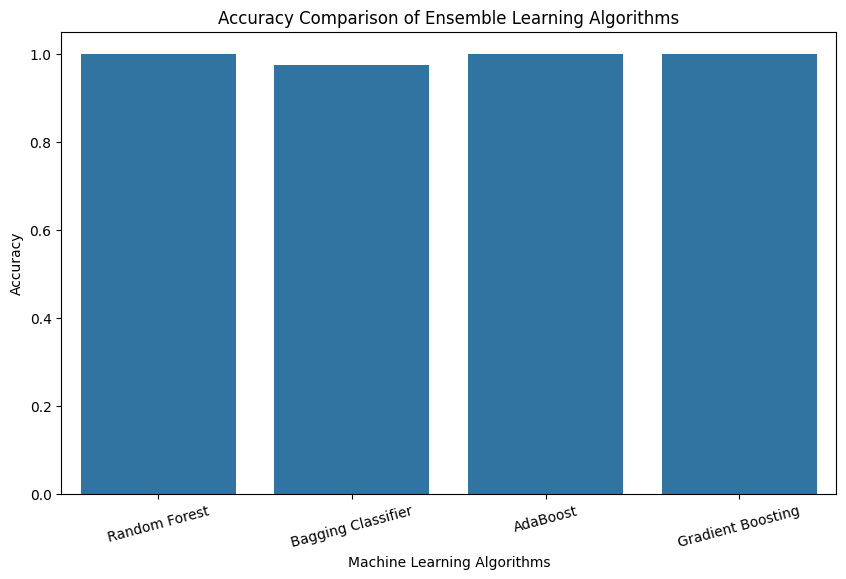

In [16]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='Accuracy'
)

plt.title('Accuracy Comparison of Ensemble Learning Algorithms')
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Accuracy')

plt.ylim(0, 1.05)
plt.xticks(rotation=15)

plt.savefig('algorithm_accuracy_comparison.png', dpi=300)
plt.show()


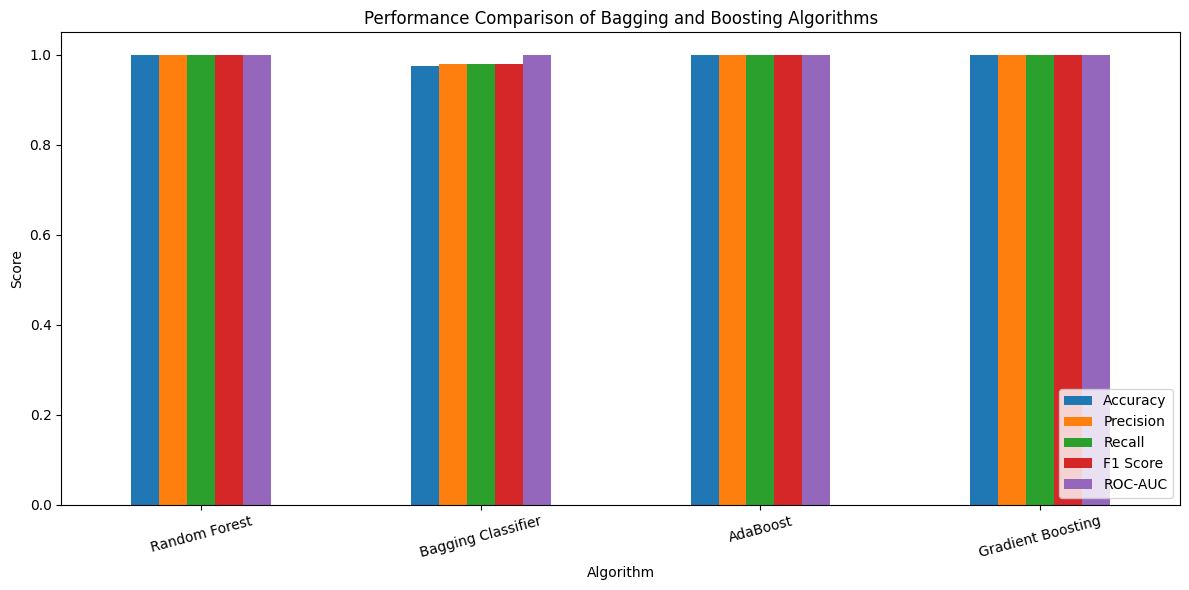

In [17]:

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

results_df.set_index('Algorithm')[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of Bagging and Boosting Algorithms')
plt.ylabel('Score')
plt.xlabel('Algorithm')
plt.ylim(0, 1.05)

plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig('complete_model_comparison.png', dpi=300)
plt.show()


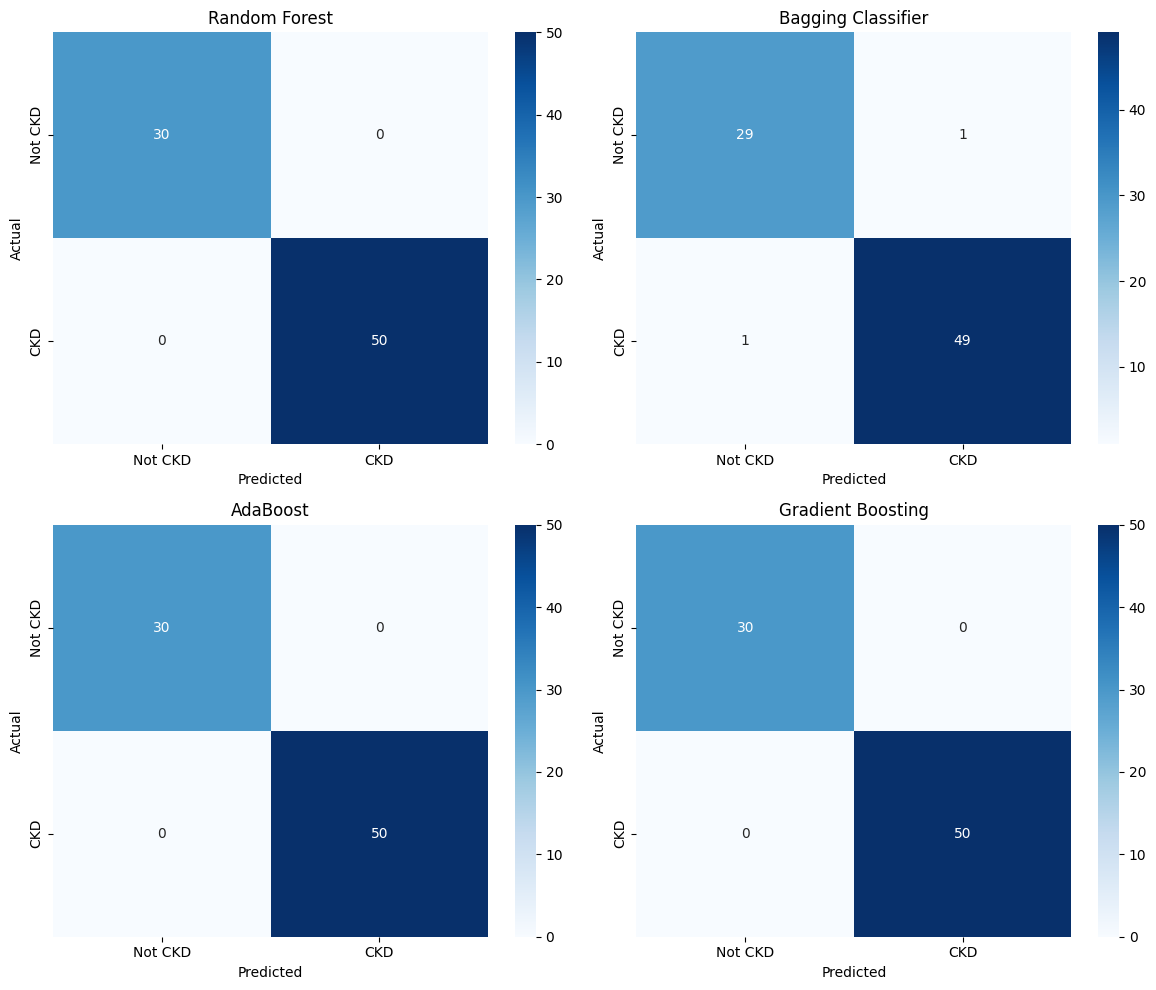

In [18]:

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, model) in zip(axes.flatten(), models.items()):

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Not CKD', 'CKD'],
        yticklabels=['Not CKD', 'CKD'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300)
plt.show()


In [19]:

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create complete pipelines for each algorithm
cv_models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    'Bagging Classifier': BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

scoring = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc'
]

cv_results = []

for name, model in cv_models.items():

    # Include preprocessing inside the pipeline
    full_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    scores = cross_validate(
        full_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Algorithm': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean(),
        'Accuracy Std': scores['test_accuracy'].std()
    })

cv_results_df = pd.DataFrame(cv_results)

print("5-FOLD CROSS-VALIDATION RESULTS")

display(
    cv_results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'Accuracy Std': '{:.4f}'
    })
)


5-FOLD CROSS-VALIDATION RESULTS


,Algorithm,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Accuracy Std
0,Random Forest,0.9906,0.9901,0.9950,0.9925,0.9991,0.0125
1,Bagging Classifier,0.9719,0.9706,0.9850,0.9777,0.9927,0.0269
2,AdaBoost,0.9906,0.9901,0.9950,0.9925,0.9997,0.0125
3,Gradient Boosting,0.9875,0.9812,1.0000,0.9903,0.9981,0.0182


<Figure size 1100x600 with 0 Axes>

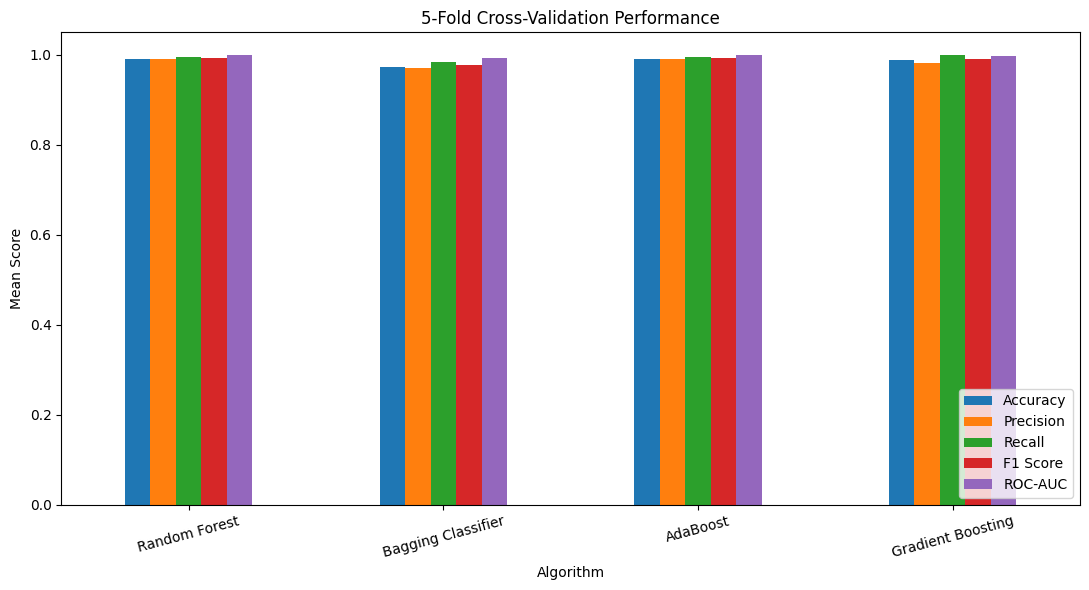

In [20]:

plt.figure(figsize=(11, 6))

cv_results_df.set_index('Algorithm')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
].plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('5-Fold Cross-Validation Performance')
plt.ylabel('Mean Score')
plt.xlabel('Algorithm')
plt.ylim(0, 1.05)

plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig('cross_validation_comparison.png', dpi=300)
plt.show()


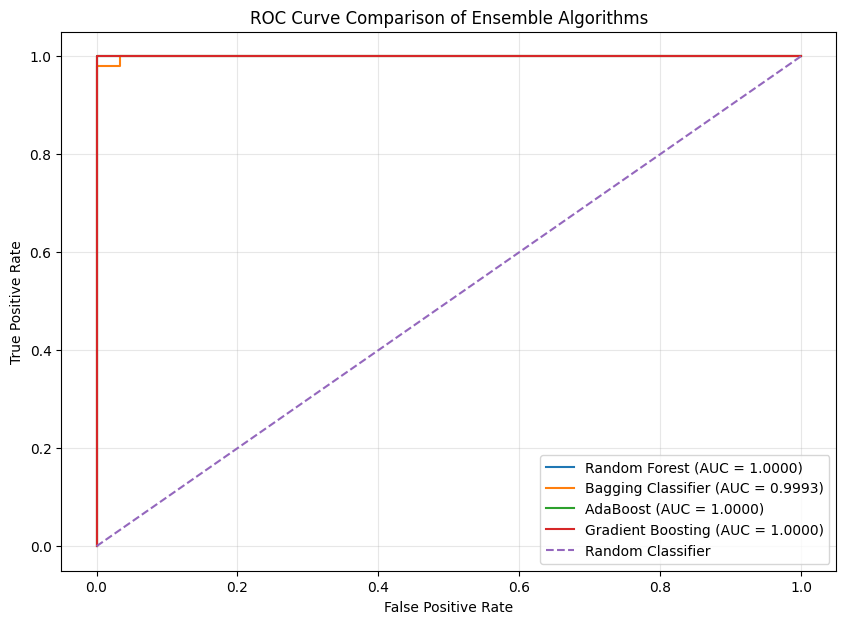

In [21]:

plt.figure(figsize=(10, 7))

for name, model in models.items():

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.4f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve Comparison of Ensemble Algorithms')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.savefig('roc_curve_comparison.png', dpi=300)
plt.show()


In [22]:

from sklearn.inspection import permutation_importance

# Create complete pipelines
fitted_pipelines = {}

for name, model in cv_models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    fitted_pipelines[name] = pipeline

print("All complete pipelines fitted successfully!")

# Calculate permutation importance
importance_results = {}

for name, pipeline in fitted_pipelines.items():

    importance = permutation_importance(
        pipeline,
        X_test,
        y_test,
        n_repeats=10,
        random_state=42,
        scoring='roc_auc',
        n_jobs=-1
    )

    importance_results[name] = pd.Series(
        importance.importances_mean,
        index=X_test.columns
    ).sort_values(ascending=False)

# Display top 10 features for each model
for name, importance in importance_results.items():

    print(f"\nTop 10 Features - {name}")

    display(
        importance.head(10).to_frame(
            name='Importance Score'
        )
    )


All complete pipelines fitted successfully!

Top 10 Features - Random Forest


,Importance Score
sg,1.640000e-02
sc,1.100000e-03
pcv,3.333333e-04
htn,3.333333e-04
hemo,2.666667e-04
ba,4.440892e-17
pc,2.220446e-17
age,2.220446e-17
rc,1.110223e-17
pot,1.110223e-17



Top 10 Features - Bagging Classifier


,Importance Score
sg,5.830000e-02
hemo,2.353333e-02
htn,3.433333e-03
rc,3.166667e-03
sc,2.700000e-03
bu,1.466667e-03
pcv,4.000000e-04
al,4.000000e-04
appet,9.992007e-17
pe,7.771561e-17



Top 10 Features - AdaBoost


,Importance Score
hemo,1.033333e-02
sg,9.866667e-03
sc,6.133333e-03
al,2.000000e-04
bgr,1.110223e-17
su,0.000000e+00
bp,0.000000e+00
age,0.000000e+00
pcc,0.000000e+00
pc,0.000000e+00



Top 10 Features - Gradient Boosting


,Importance Score
sg,5.946667e-02
hemo,1.453333e-02
sc,1.066667e-03
rbc,1.110223e-17
pcv,1.110223e-17
al,0.000000e+00
bp,0.000000e+00
age,0.000000e+00
pcc,0.000000e+00
pc,0.000000e+00


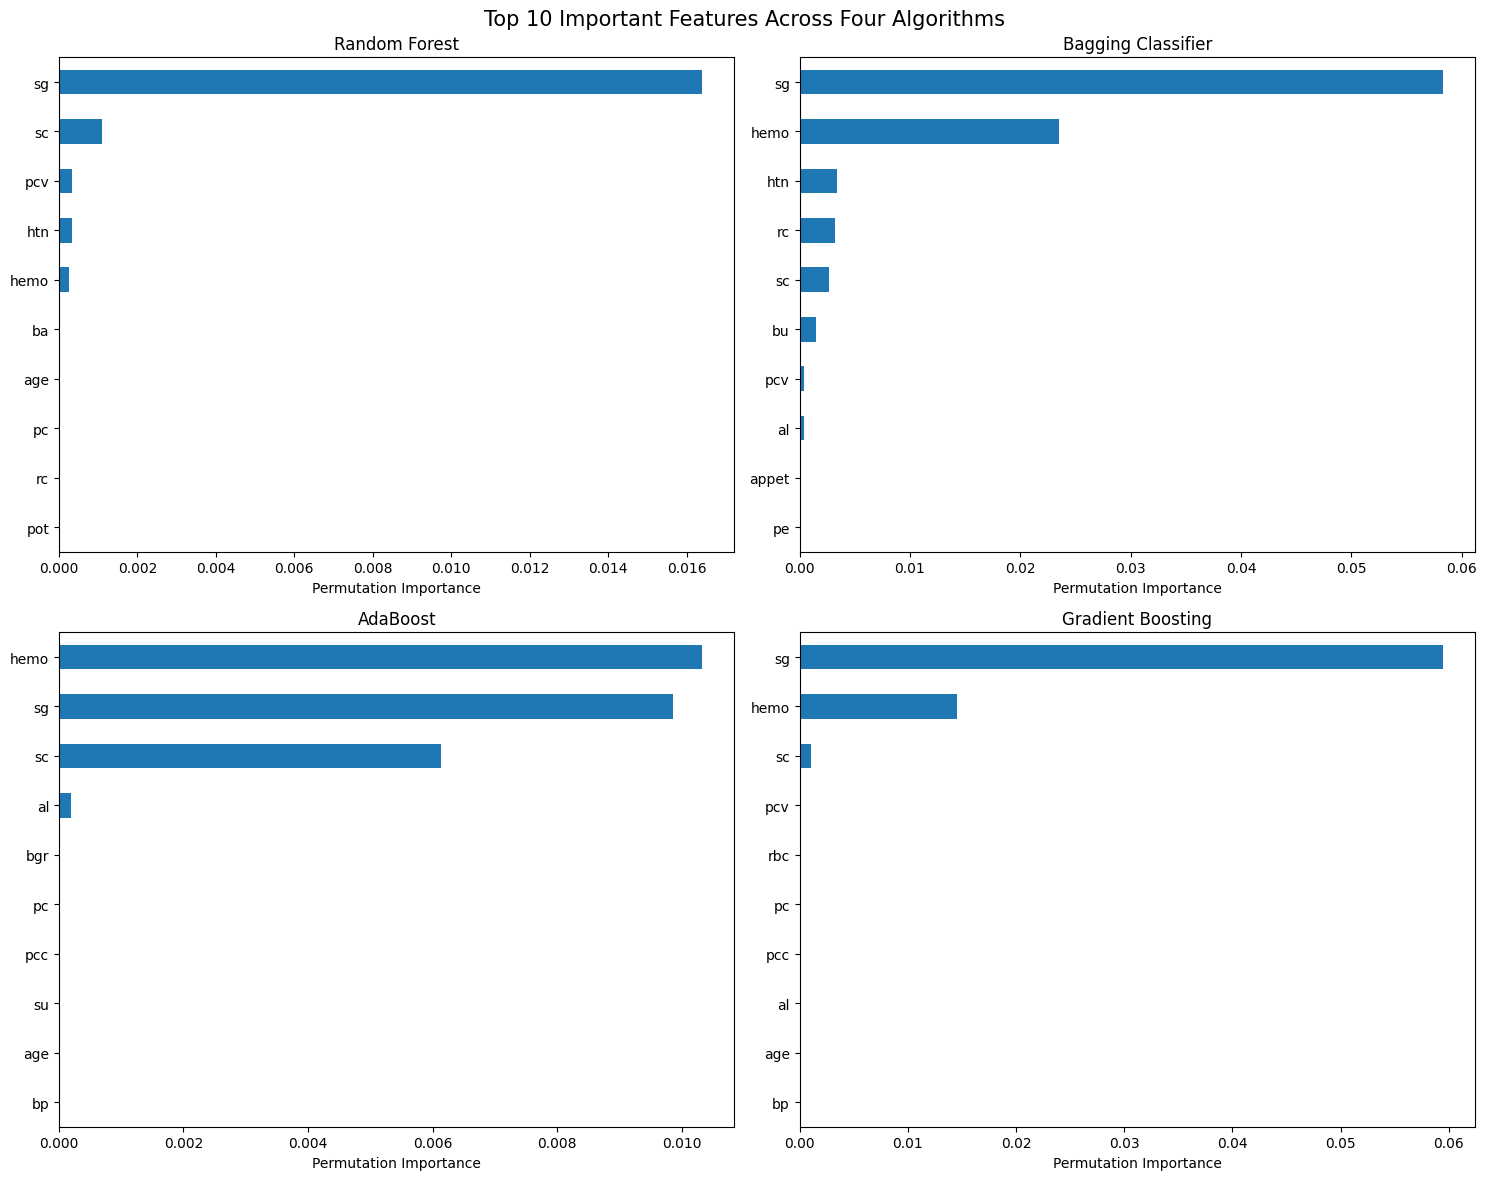

In [23]:

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for ax, (name, importance) in zip(
    axes.flatten(),
    importance_results.items()
):

    top_features = importance.head(10).sort_values()

    top_features.plot(
        kind='barh',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Permutation Importance')

plt.suptitle(
    'Top 10 Important Features Across Four Algorithms',
    fontsize=15
)

plt.tight_layout()
plt.savefig('feature_importance_comparison.png', dpi=300)
plt.show()


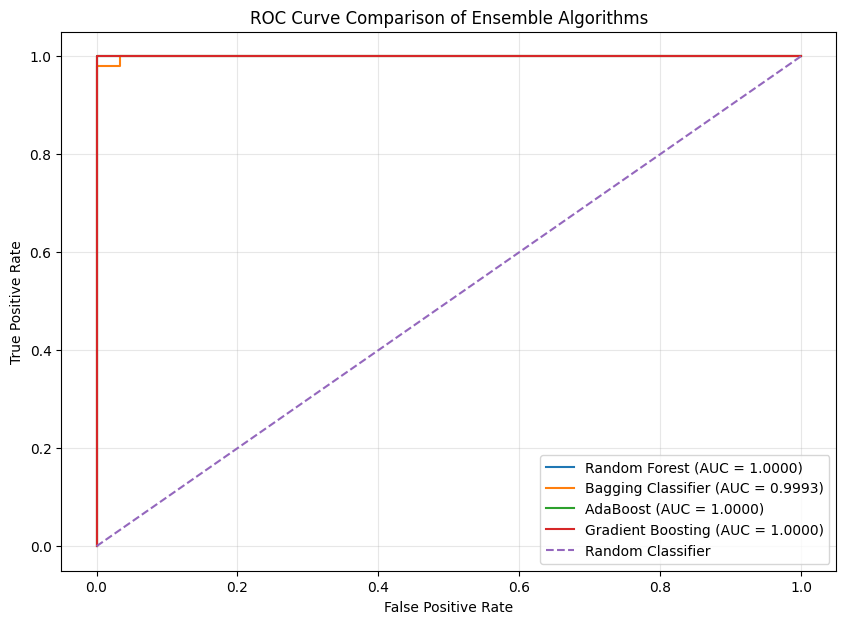

In [24]:

plt.figure(figsize=(10, 7))

for name, model in models.items():

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.4f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve Comparison of Ensemble Algorithms')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.savefig('roc_curve_comparison.png', dpi=300)
plt.show()


In [25]:

from sklearn.inspection import permutation_importance

# Create complete pipelines
fitted_pipelines = {}

for name, model in cv_models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    fitted_pipelines[name] = pipeline

print("All complete pipelines fitted successfully!")

# Calculate permutation importance
importance_results = {}

for name, pipeline in fitted_pipelines.items():

    importance = permutation_importance(
        pipeline,
        X_test,
        y_test,
        n_repeats=10,
        random_state=42,
        scoring='roc_auc',
        n_jobs=-1
    )

    importance_results[name] = pd.Series(
        importance.importances_mean,
        index=X_test.columns
    ).sort_values(ascending=False)

# Display top 10 features for each model
for name, importance in importance_results.items():

    print(f"\nTop 10 Features - {name}")

    display(
        importance.head(10).to_frame(
            name='Importance Score'
        )
    )


All complete pipelines fitted successfully!

Top 10 Features - Random Forest


,Importance Score
sg,1.640000e-02
sc,1.100000e-03
pcv,3.333333e-04
htn,3.333333e-04
hemo,2.666667e-04
ba,4.440892e-17
pc,2.220446e-17
age,2.220446e-17
rc,1.110223e-17
pot,1.110223e-17



Top 10 Features - Bagging Classifier


,Importance Score
sg,5.830000e-02
hemo,2.353333e-02
htn,3.433333e-03
rc,3.166667e-03
sc,2.700000e-03
bu,1.466667e-03
pcv,4.000000e-04
al,4.000000e-04
appet,9.992007e-17
pe,7.771561e-17



Top 10 Features - AdaBoost


,Importance Score
hemo,1.033333e-02
sg,9.866667e-03
sc,6.133333e-03
al,2.000000e-04
bgr,1.110223e-17
su,0.000000e+00
bp,0.000000e+00
age,0.000000e+00
pcc,0.000000e+00
pc,0.000000e+00



Top 10 Features - Gradient Boosting


,Importance Score
sg,5.946667e-02
hemo,1.453333e-02
sc,1.066667e-03
rbc,1.110223e-17
pcv,1.110223e-17
al,0.000000e+00
bp,0.000000e+00
age,0.000000e+00
pcc,0.000000e+00
pc,0.000000e+00


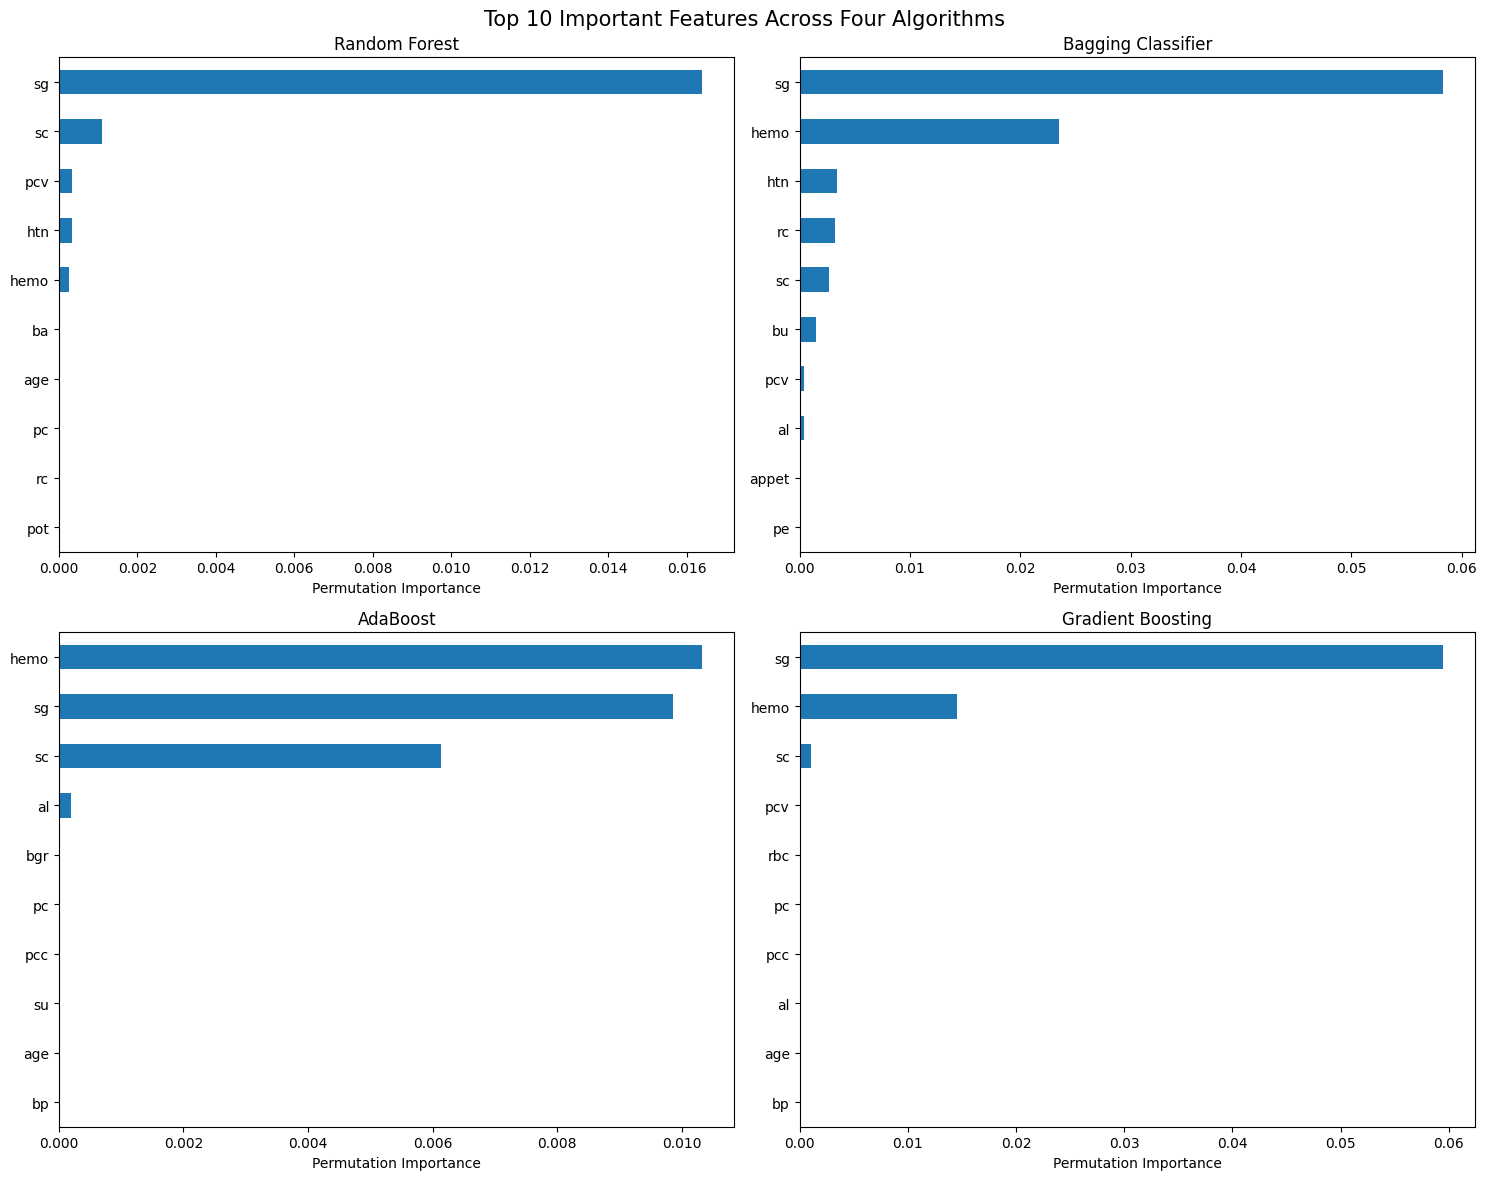

In [26]:

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for ax, (name, importance) in zip(
    axes.flatten(),
    importance_results.items()
):

    top_features = importance.head(10).sort_values()

    top_features.plot(
        kind='barh',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Permutation Importance')

plt.suptitle(
    'Top 10 Important Features Across Four Algorithms',
    fontsize=15
)

plt.tight_layout()
plt.savefig('feature_importance_comparison.png', dpi=300)
plt.show()


In [27]:

from sklearn.base import clone
import joblib

# Create independent pipelines for all four models
final_pipelines = {}

for name, model in cv_models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', clone(model))
    ])

    # Train using original, unprocessed training data
    pipeline.fit(X_train, y_train)

    final_pipelines[name] = pipeline

    print(f"{name} pipeline completed!")

print("\nAll four deployment pipelines are ready!")


Random Forest pipeline completed!
Bagging Classifier pipeline completed!
AdaBoost pipeline completed!
Gradient Boosting pipeline completed!

All four deployment pipelines are ready!


In [28]:

# Create model bundle
model_bundle = {
    'models': final_pipelines,

    'target_mapping': {
        0: 'Not CKD',
        1: 'CKD'
    },

    'features': X.columns.tolist(),

    'default_model': 'Random Forest',

    'project_name': 'Chronic Kidney Disease Prediction',

    'algorithms': list(final_pipelines.keys())
}

# Save complete model bundle
joblib.dump(
    model_bundle,
    'ckd_prediction_pipeline.pkl'
)

print("Model bundle saved successfully!")
print("\nAvailable models:")

for name in model_bundle['algorithms']:
    print("-", name)


Model bundle saved successfully!

Available models:
- Random Forest
- Bagging Classifier
- AdaBoost
- Gradient Boosting


In [29]:

# Save initial test performance
results_df.to_csv(
    'model_performance.csv',
    index=False
)

# Save cross-validation performance
cv_results_df.to_csv(
    'cross_validation_results.csv',
    index=False
)

# Save feature importance
importance_df = pd.concat(
    importance_results,
    names=['Algorithm', 'Feature']
).reset_index(name='Importance')

importance_df.to_csv(
    'feature_importance.csv',
    index=False
)

print("All performance reports exported!")


All performance reports exported!


In [30]:

import zipfile
import os

artifacts = [
    'ckd_prediction_pipeline.pkl',
    'model_performance.csv',
    'cross_validation_results.csv',
    'feature_importance.csv',
    'target_distribution.png',
    'algorithm_accuracy_comparison.png',
    'complete_model_comparison.png',
    'confusion_matrices.png',
    'cross_validation_comparison.png',
    'roc_curve_comparison.png',
    'feature_importance_comparison.png'
]

with zipfile.ZipFile(
    'CKD_Project_Artifacts.zip',
    'w',
    zipfile.ZIP_DEFLATED
) as zip_file:

    for file in artifacts:
        if os.path.exists(file):
            zip_file.write(file)

print("Project artifacts packaged successfully!")

from google.colab import files

files.download('CKD_Project_Artifacts.zip')


Project artifacts packaged successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
mkdir -p ~/CKD-Prediction/{models,templates,static/css,static/js}
cd ~/CKD-Prediction


SyntaxError: invalid syntax (256079453.py, line 1)

In [32]:
import sys
import sklearn
import numpy
import pandas
import scipy
import joblib

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("SciPy:", scipy.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Scikit-learn: 1.6.1
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
Joblib: 1.6.0
